# The Transformer Encoder from Scratch

Attention lets tokens share information. This notebook builds everything around it that turns attention into a full **transformer encoder**:

1. **Positional encoding:** telling the model where each word sits
2. **Layer normalization:** keeping the numbers well-behaved
3. **Feed-forward network:** letting each token "think" on its own
4. **The encoder block:** attention + FFN, each wrapped in Add & Norm
5. **Proof that order matters:** an experiment where the encoder fails without positions and succeeds with them

The running example is the sentence **"bank of river"** from the course.
This notebook comes from Sessions 5–6 of [Master Transformers from Scratch: BERT, ViT & AI Search](https://www.udemy.com/course/master-transformers-from-scratch-bert-vit-ai-search/).

In [1]:
# On Colab, fetch encoder.py from the repo. Locally it's already next to this notebook.
import os, urllib.request
if not os.path.exists("encoder.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/seyedvahidmirnezami/transformer-encoder-pytorch/main/encoder.py",
        "encoder.py",
    )

import torch
import matplotlib.pyplot as plt
from encoder import sinusoidal_positional_encoding, FeedForward, EncoderBlock, TransformerEncoder

torch.set_printoptions(precision=3, sci_mode=False)

Matplotlib is building the font cache; this may take a moment.


## 1. Positional encoding

Self-attention compares every token with every other token, but nothing in it says *where* a token is.
"dog bites man" and "man bites dog" would look identical. The fix is to add a unique position pattern to each embedding:

```
PE(pos, 2i)   = sin(pos / 10000^(2i / d_model))
PE(pos, 2i+1) = cos(pos / 10000^(2i / d_model))
```

With `d_model = 4`, the first three positions are:

In [2]:
pe = sinusoidal_positional_encoding(max_len=3, d_model=4)
pe

tensor([[ 0.000,  1.000,  0.000,  1.000],
        [ 0.841,  0.540,  0.010,  1.000],
        [ 0.909, -0.416,  0.020,  1.000]])

Now add them to the "bank of river" embeddings. We **add** rather than concatenate, so the size stays the same.

In [3]:
X = torch.tensor([
    [1., 0., 1., 0.],   # bank
    [0., 1., 0., 1.],   # of
    [1., 1., 0., 0.],   # river
])
X + pe

tensor([[1.000, 1.000, 1.000, 1.000],
        [0.841, 1.540, 0.010, 2.000],
        [1.909, 0.584, 0.020, 1.000]])

Across more positions and dimensions, the pattern looks like this. Early dimensions change quickly from one position to the next, later ones change slowly, so every position gets its own fingerprint.

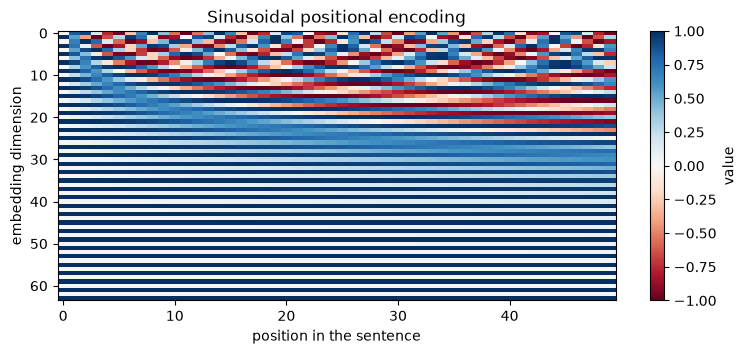

In [4]:
table = sinusoidal_positional_encoding(max_len=50, d_model=64)
plt.figure(figsize=(9, 3.5))
plt.imshow(table.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("position in the sentence")
plt.ylabel("embedding dimension")
plt.colorbar(label="value")
plt.title("Sinusoidal positional encoding")
plt.show()

## 2. Layer normalization

After attention, each token vector is added back to its input (the **residual connection**), then normalized:

```
LayerNorm(x) = γ · (x − mean) / std + β
```

Each token is normalized on its own, across its features. Here is the vector for "bank" after the residual step in the course example:

In [5]:
x = torch.tensor([[2.0, 1.0, 2.0, 1.436]])
print("mean:", x.mean().item(), " std:", x.std(unbiased=False).item())
torch.nn.LayerNorm(4)(x)  # γ = 1, β = 0 before training

mean: 1.6089999675750732  std: 0.42028918862342834


tensor([[ 0.930, -1.449,  0.930, -0.412]], grad_fn=<NativeLayerNormBackward0>)

## 3. Feed-forward network

Attention is where tokens **communicate**. The feed-forward network is where each token **thinks** on its own:
expand to `d_ff` (usually 4 × `d_model`), apply ReLU, compress back.

In [6]:
ffn = FeedForward(d_model=512, d_ff=2048)
tokens = torch.randn(1, 3, 512)
print("in :", tuple(tokens.shape))
print("out:", tuple(ffn(tokens).shape))
print("parameters:", sum(p.numel() for p in ffn.parameters()))

in : (1, 3, 512)
out: (1, 3, 512)
parameters: 2099712


## 4. The encoder block

```
Z      = LayerNorm(X + MultiHeadAttention(X))
output = LayerNorm(Z + FeedForward(Z))
```

The output has the **same shape** as the input, so blocks stack. BERT-base stacks 12 of them.

In [7]:
block = EncoderBlock(d_model=64, num_heads=4, d_ff=256)
x = torch.randn(2, 5, 64)          # 2 sentences, 5 tokens, 64-dim vectors
out, attention = block(x)
print("input    ", tuple(x.shape))
print("output   ", tuple(out.shape))
print("attention", tuple(attention.shape), "(batch, heads, n, n)")

input     (2, 5, 64)
output    (2, 5, 64)
attention (2, 4, 5, 5) (batch, heads, n, n)


## 5. Without positions, attention is order-blind

Build an encoder with positional encoding switched **off**, feed it a sentence and a shuffled copy, and compare the `[CLS]` output (position 0).

In [8]:
def cls_vector(model, ids):
    model.eval()
    with torch.no_grad():
        hidden, _ = model(torch.tensor([ids]))
    return hidden[0, 0]

sentence = [1, 5, 6, 7, 8, 9]   # 1 = [CLS]
shuffled = [1, 9, 7, 5, 8, 6]   # same words, different order

for use_pe in (False, True):
    torch.manual_seed(0)
    model = TransformerEncoder(vocab_size=30, d_model=16, num_heads=4, d_ff=32, use_positional_encoding=use_pe)
    same = torch.allclose(cls_vector(model, sentence), cls_vector(model, shuffled), atol=1e-5)
    print(f"positional encoding {'on ' if use_pe else 'off'}: shuffled sentence gives the same [CLS] vector? {same}")

positional encoding off: shuffled sentence gives the same [CLS] vector? True
positional encoding on : shuffled sentence gives the same [CLS] vector? False


## 6. An experiment: does A come before B?

Each sequence has one `A` and one `B` hidden among random filler tokens. The label is 1 if `A` comes first.
Both classes contain exactly the same words, so the only signal is **order**.

We train the same small encoder twice, without and with positional encoding. This takes a few seconds on a CPU.

In [9]:
if not os.path.exists("train_order_task.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/seyedvahidmirnezami/transformer-encoder-pytorch/main/train_order_task.py",
        "train_order_task.py",
    )
from train_order_task import train

for use_pe in (False, True):
    acc = train(use_positional_encoding=use_pe)
    print(f"{'with   ' if use_pe else 'without'} positional encoding: test accuracy = {acc:.1%}")

without positional encoding: test accuracy = 50.1%


with    positional encoding: test accuracy = 100.0%


Without positional encoding the model is stuck at a coin flip (about 50%). With it, the same model solves the task.
Word order lives **only** in the positional encoding.

## Where to go next

This encoder is exactly what BERT is built from. The full course continues with BERT pretraining in PyTorch,
fine-tuning for classification and NER, Vision Transformers, and two-tower semantic search.

👉 [Master Transformers from Scratch: BERT, ViT & AI Search](https://www.udemy.com/course/master-transformers-from-scratch-bert-vit-ai-search/)